# Lab Sheet-10 · Capstone Project 1: Loan Approval Prediction System
**MCA III Semester (Session 2026–2027) – Capstone Machine Learning Projects**

**Objective:** an end-to-end ML application that predicts loan approval from applicant details (income, education, employment, loan amount, credit history, marital status) with a simple prediction interface.

## Dataset (Kaggle)
[Loan Prediction Problem Dataset (altruistdelhite04)](https://www.kaggle.com/datasets/altruistdelhite04/loan-prediction-problem-dataset) – `train_*.csv` (614 applicants, target `Loan_Status` Y/N).

**Setup:** download the CSV file(s) from the Kaggle link(s) above and place them in the **same folder as this notebook** (or in a `data/` sub-folder). The file name is searched automatically.

## System architecture & flowchart
```
flowchart LR
    A[Kaggle CSV] --> B[EDA & Visualisation]
    B --> C[Preprocessing<br/>impute · feature engineering · scale · one-hot]
    C --> D[Train/Test split + 5-fold CV]
    D --> E[Compare 6 algorithms]
    E --> F[Tune best model<br/>GridSearchCV]
    F --> G[Evaluate<br/>Acc · Prec · Rec · F1 · ROC-AUC]
    G --> H[(Save pipeline<br/>loan_model.joblib)]
    H --> I[Streamlit / widget UI]
    I --> J[Approved ✔ / Rejected ✘ + probability]
```

In [32]:
# !pip install -q pandas numpy matplotlib seaborn scikit-learn joblib streamlit ipywidgets
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, RocCurveDisplay, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42

In [33]:
import os



## 1. Load data

In [34]:
df = pd.read_csv("train_u6lujuX_CVtuZ9i.csv")   # use your exact file name
print(df.shape)
df.head()

(614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## 2. Exploratory Data Analysis

In [35]:
df.info()
display(df.describe().T.round(2))
miss = df.isna().sum(); display(miss[miss > 0].to_frame("missing").assign(pct=lambda x: (x.missing / len(df) * 100).round(1)))
print("Duplicates:", df.duplicated().sum())
print(df["Loan_Status"].value_counts(normalize=True).round(3))

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.4 KB


,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,614.0,5403.46,6109.04,150.0,2877.5,3812.5,5795.00,81000.0
CoapplicantIncome,614.0,1621.25,2926.25,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,146.41,85.59,9.0,100.0,128.0,168.00,700.0
Loan_Amount_Term,600.0,342.00,65.12,12.0,360.0,360.0,360.00,480.0
Credit_History,564.0,0.84,0.36,0.0,1.0,1.0,1.00,1.0


,missing,pct
Gender,13,2.1
Married,3,0.5
Dependents,15,2.4
Self_Employed,32,5.2
LoanAmount,22,3.6
Loan_Amount_Term,14,2.3
Credit_History,50,8.1


Duplicates: 0
Loan_Status
Y    0.687
N    0.313
Name: proportion, dtype: float64


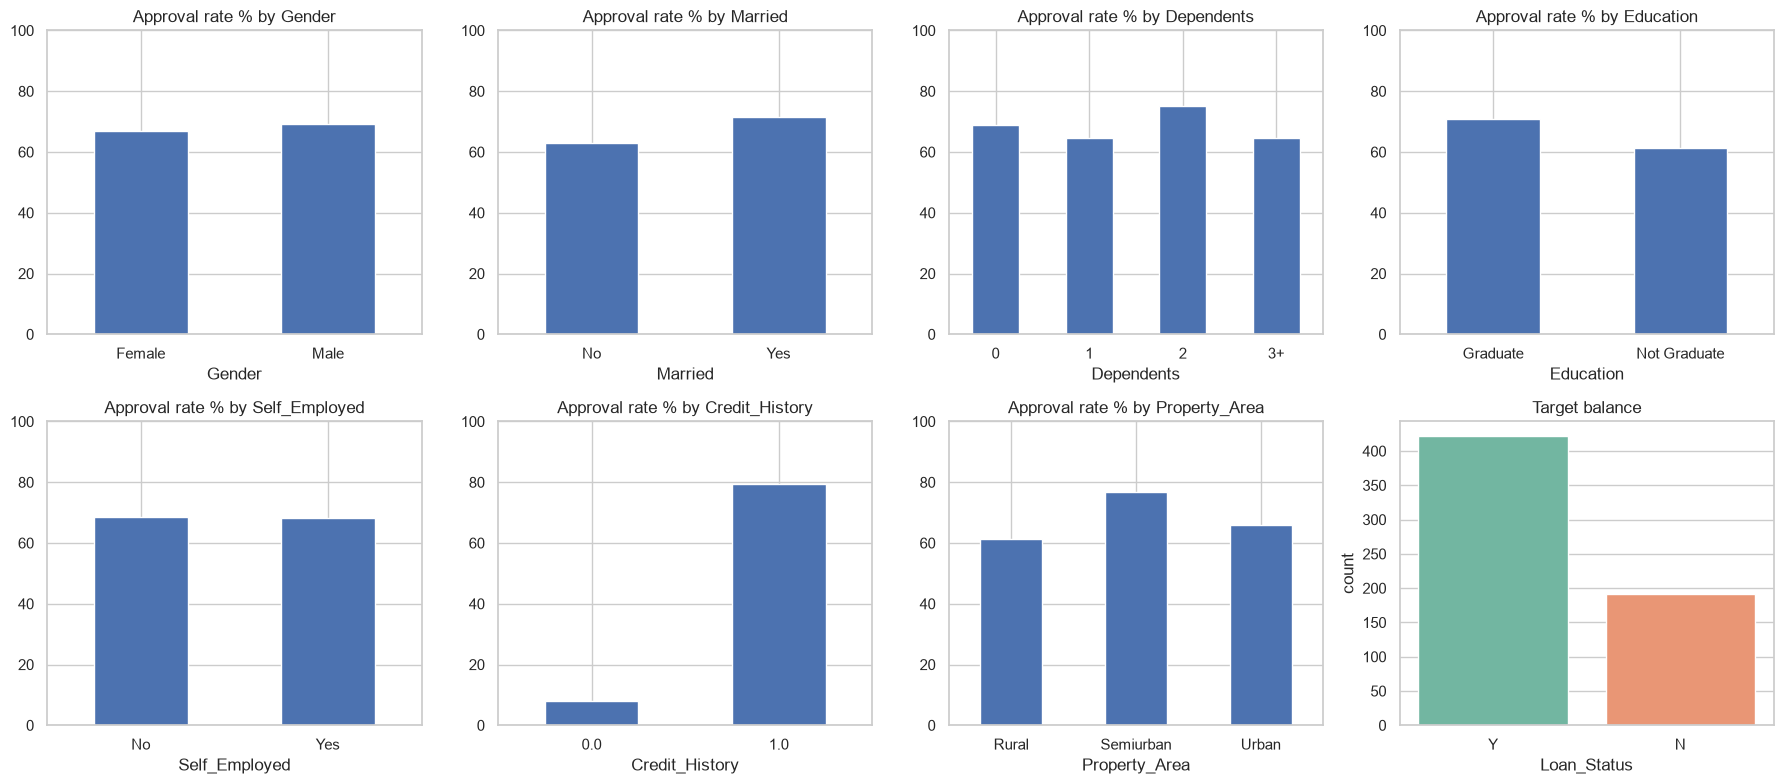

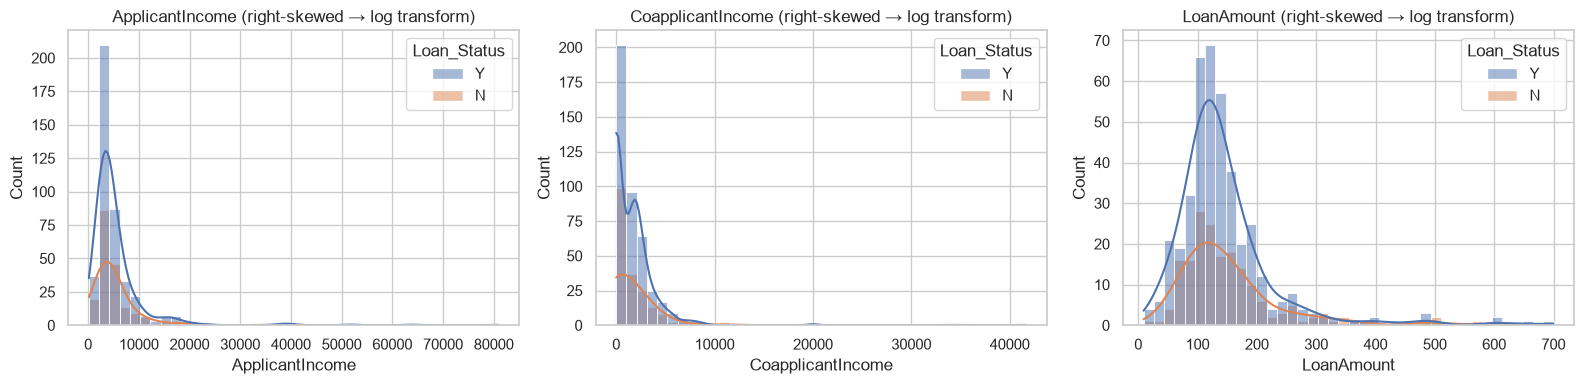

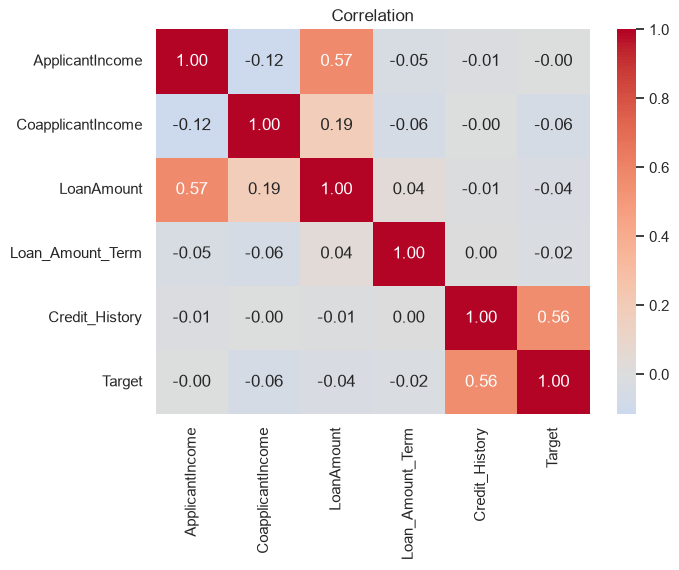

In [36]:
cat_cols = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Credit_History", "Property_Area"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), cat_cols):
    (df.groupby(c)["Loan_Status"].apply(lambda s: (s == "Y").mean() * 100)).plot.bar(ax=ax, color="#4c72b0")
    ax.set_title(f"Approval rate % by {c}"); ax.set_ylim(0, 100); ax.tick_params(axis="x", rotation=0)
sns.countplot(data=df, x="Loan_Status", ax=axes[1, 3], palette="Set2"); axes[1, 3].set_title("Target balance")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]):
    sns.histplot(data=df, x=c, hue="Loan_Status", kde=True, ax=ax, bins=40); ax.set_title(f"{c} (right-skewed → log transform)")
plt.tight_layout(); plt.show()
num = df.select_dtypes("number").assign(Target=(df["Loan_Status"] == "Y").astype(int))
plt.figure(figsize=(7, 5)); sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0); plt.title("Correlation"); plt.show()

**EDA takeaways:** `Credit_History` is by far the strongest driver of approval; income and loan amount are heavily right-skewed (→ log transform); several columns have a few % missing values (→ impute, don't drop).

## 3. Preprocessing & feature engineering
* Target → `1` (Y) / `0` (N); drop `Loan_ID` (identifier, no signal).
* **New features:** `TotalIncome`, `LoanAmount_log`, `TotalIncome_log`, `EMI` (loan ÷ term), `Balance_Income` (income left after EMI).
* **Imputation inside a `Pipeline`:** median for numeric, most-frequent for categorical – fitted on training folds only → **no data leakage**.
* **Encoding / scaling:** One-hot for categoricals, standard-scaling for numeric.

In [37]:
def add_features(d):
    d = d.copy()
    d["Dependents"] = d["Dependents"].astype(object)
    d["Credit_History"] = d["Credit_History"].astype(float)
    d["TotalIncome"] = d["ApplicantIncome"] + d["CoapplicantIncome"]
    d["TotalIncome_log"] = np.log1p(d["TotalIncome"])
    d["LoanAmount_log"] = np.log1p(d["LoanAmount"])
    d["EMI"] = d["LoanAmount"] / d["Loan_Amount_Term"] * 1000     # loan amount is in thousands
    d["Balance_Income"] = d["TotalIncome"] - d["EMI"]
    return d


from sklearn.preprocessing import FunctionTransformer
NUM = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term", "Credit_History",
       "TotalIncome_log", "LoanAmount_log", "EMI", "Balance_Income"]
CAT = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Property_Area"]
FEATURES = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "ApplicantIncome", "CoapplicantIncome",
            "LoanAmount", "Loan_Amount_Term", "Credit_History", "Property_Area"]   # raw inputs the user supplies


def make_preprocessor():
    num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    cat_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                         ("oh", OneHotEncoder(handle_unknown="ignore"))])
    return Pipeline([("fe", FunctionTransformer(add_features)),
                     ("ct", ColumnTransformer([("num", num_pipe, NUM), ("cat", cat_pipe, CAT)]))])


X = df[FEATURES]
y = (df["Loan_Status"] == "Y").astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
print("train", X_train.shape, "test", X_test.shape, "| approval rate train/test:", y_train.mean().round(3), y_test.mean().round(3))

train (491, 11) test (123, 11) | approval rate train/test: 0.686 0.691


## 4. Compare multiple algorithms (5-fold stratified cross-validation)

,Model,accuracy,precision,recall,f1,roc_auc,acc_std
0,KNN,0.7962,0.7785,0.9852,0.8695,0.6890,0.0490
1,Logistic Regression,0.7942,0.7820,0.9733,0.8669,0.7140,0.0448
2,Random Forest,0.7942,0.7819,0.9733,0.8669,0.7750,0.0497
3,SVM (RBF),0.7922,0.7787,0.9763,0.8661,0.7304,0.0423
4,Decision Tree,0.7759,0.7765,0.9497,0.8537,0.6784,0.0373
5,Gradient Boosting,0.7657,0.7783,0.9230,0.8436,0.7381,0.0599


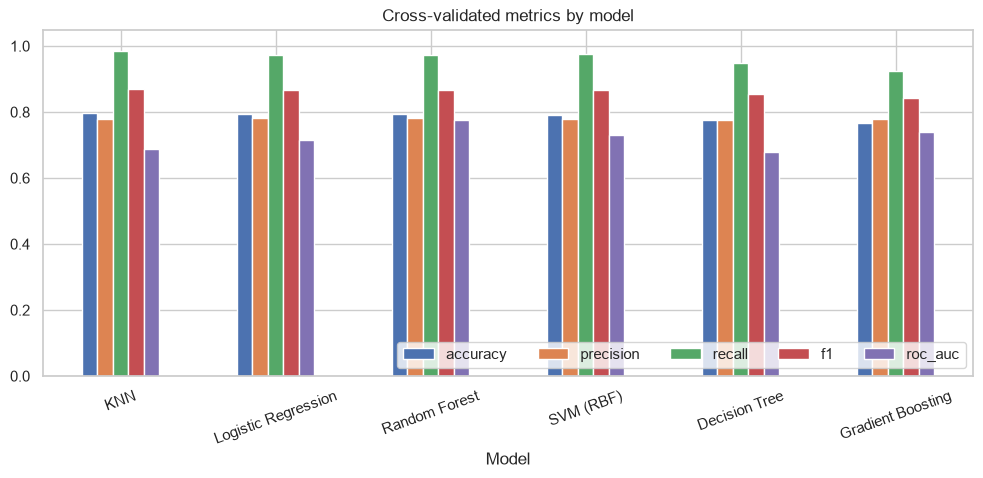

In [38]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(15),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "Random Forest": RandomForestClassifier(300, max_depth=6, random_state=SEED),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
    "SVM (RBF)": SVC(probability=True, random_state=SEED),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
rows = []
for name, mdl in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", mdl)])
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"Model": name, **{m: s[f"test_{m}"].mean() for m in scoring}, "acc_std": s["test_accuracy"].std()})
cmp = pd.DataFrame(rows).sort_values("f1", ascending=False).reset_index(drop=True)
display(cmp.round(4))
cmp.set_index("Model")[scoring].plot.bar(figsize=(12, 4.5), rot=20, title="Cross-validated metrics by model"); plt.ylim(0, 1.05); plt.legend(loc="lower right", ncol=5); plt.show()

**Which metric?** The classes are imbalanced (~2:1 approved), so *accuracy alone is misleading*. From a bank's view a false approval (default risk) is costly, while a false rejection loses business – so we look at **precision, recall, F1 and ROC-AUC** together and select by F1 / ROC-AUC.

## 5. Hyper-parameter tuning of the best candidates

In [39]:
grids = {
    "Logistic Regression": (LogisticRegression(max_iter=1000), {"clf__C": [.01, .1, 1, 10], "clf__class_weight": [None, "balanced"]}),
    "Random Forest": (RandomForestClassifier(random_state=SEED), {"clf__n_estimators": [200, 400], "clf__max_depth": [3, 5, 8], "clf__min_samples_leaf": [1, 5]}),
}
tuned = {}
for name, (est, pg) in grids.items():
    gs = GridSearchCV(Pipeline([("prep", make_preprocessor()), ("clf", est)]), pg, cv=cv, scoring="f1", n_jobs=-1).fit(X_train, y_train)
    tuned[name] = gs; print(f"{name}: best CV F1 = {gs.best_score_:.4f} | {gs.best_params_}")
best_name = max(tuned, key=lambda k: tuned[k].best_score_)
best_model = tuned[best_name].best_estimator_
print("\nSelected model:", best_name)

Logistic Regression: best CV F1 = 0.8699 | {'clf__C': 0.01, 'clf__class_weight': None}
Random Forest: best CV F1 = 0.8684 | {'clf__max_depth': 8, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 200}

Selected model: Logistic Regression


## 6. Final evaluation on the untouched test set

Accuracy 0.8537 | Precision 0.8317 | Recall 0.9882 | F1 0.9032 | ROC-AUC 0.8477

              precision    recall  f1-score   support

    Rejected       0.95      0.55      0.70        38
    Approved       0.83      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.77      0.80       123
weighted avg       0.87      0.85      0.84       123



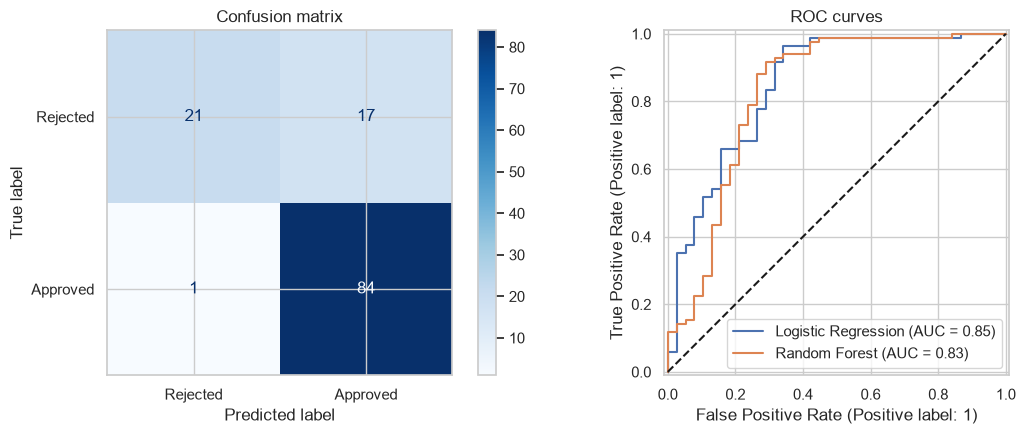

In [40]:
pred = best_model.predict(X_test); proba = best_model.predict_proba(X_test)[:, 1]
print(f"Accuracy {accuracy_score(y_test, pred):.4f} | Precision {precision_score(y_test, pred):.4f} | Recall {recall_score(y_test, pred):.4f} | "
      f"F1 {f1_score(y_test, pred):.4f} | ROC-AUC {roc_auc_score(y_test, proba):.4f}\n")
print(classification_report(y_test, pred, target_names=["Rejected", "Approved"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Rejected", "Approved"], cmap="Blues", ax=axes[0]); axes[0].set_title("Confusion matrix")
for n_, g in tuned.items(): RocCurveDisplay.from_estimator(g.best_estimator_, X_test, y_test, ax=axes[1], name=n_)
axes[1].plot([0, 1], [0, 1], "k--"); axes[1].set_title("ROC curves"); plt.tight_layout(); plt.savefig("loan_eval.png", dpi=130); plt.show()

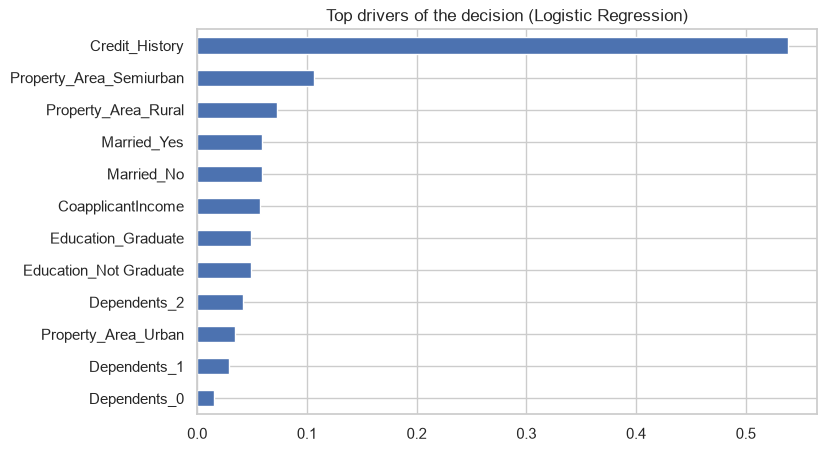

In [41]:
clf = best_model.named_steps["clf"]
names = best_model.named_steps["prep"].named_steps["ct"].get_feature_names_out()
imp = clf.feature_importances_ if hasattr(clf, "feature_importances_") else np.abs(clf.coef_[0])
s = pd.Series(imp, index=[n.split("__")[1] for n in names]).nlargest(12).sort_values()
s.plot.barh(figsize=(8, 5), color="#4c72b0", title=f"Top drivers of the decision ({best_name})"); plt.show()

## 7. Save the trained model
The whole pipeline (feature engineering + imputation + encoding + model) is saved as one file, so the UI only needs raw applicant inputs.

In [42]:
joblib.dump({"model": best_model, "features": FEATURES, "model_name": best_name}, "loan_model.joblib")
bundle = joblib.load("loan_model.joblib")
assert (bundle["model"].predict(X_test) == pred).all()
print("Saved loan_model.joblib | reload check passed")

Saved loan_model.joblib | reload check passed


## 8. Prediction function & in-notebook interface

In [43]:
def predict_loan(applicant: dict, bundle_path="loan_model.joblib"):
    b = joblib.load(bundle_path)
    row = pd.DataFrame([applicant])[b["features"]]
    p = float(b["model"].predict_proba(row)[0, 1])
    return ("Approved" if p >= .5 else "Rejected"), p


sample = {"Gender": "Male", "Married": "Yes", "Dependents": "1", "Education": "Graduate", "Self_Employed": "No",
          "ApplicantIncome": 5800, "CoapplicantIncome": 1500, "LoanAmount": 130, "Loan_Amount_Term": 360,
          "Credit_History": 1.0, "Property_Area": "Semiurban"}
print("Good-credit applicant ->", predict_loan(sample))
print("Same applicant, no credit history ->", predict_loan({**sample, "Credit_History": 0.0}))

Good-credit applicant -> ('Approved', 0.764721304785209)
Same applicant, no credit history -> ('Rejected', 0.4039253440579862)


In [44]:
try:
    import ipywidgets as w
    from IPython.display import display, clear_output
    dd = lambda opts, v: w.Dropdown(options=opts, value=v, layout=w.Layout(width="260px"))
    ui = dict(Gender=dd(["Male", "Female"], "Male"), Married=dd(["Yes", "No"], "Yes"), Dependents=dd(["0", "1", "2", "3+"], "0"),
              Education=dd(["Graduate", "Not Graduate"], "Graduate"), Self_Employed=dd(["No", "Yes"], "No"),
              ApplicantIncome=w.IntText(value=5000, description="Applicant inc."), CoapplicantIncome=w.IntText(value=0, description="Coapp. inc."),
              LoanAmount=w.IntText(value=120, description="Loan (k)"), Loan_Amount_Term=dd([360, 180, 480, 300, 120, 84, 60, 36, 12], 360),
              Credit_History=dd([1.0, 0.0], 1.0), Property_Area=dd(["Urban", "Semiurban", "Rural"], "Urban"))
    out, btn = w.Output(), w.Button(description="Predict", button_style="primary")

    def on_click(_):
        with out:
            clear_output(); label, p = predict_loan({k: v.value for k, v in ui.items()})
            print(f"Decision: {label.upper()}  (approval probability {p:.1%})")
    btn.on_click(on_click)
    display(w.VBox([w.HTML("<h3>Loan Approval Predictor</h3>")] + [w.HBox([w.Label(k, layout=w.Layout(width="150px")), v]) for k, v in ui.items()] + [btn, out]))
except ImportError:
    print("ipywidgets not installed – use the Streamlit app below.")

ipywidgets not installed – use the Streamlit app below.


### Streamlit web app
Run in a terminal: `streamlit run app_loan.py` (the cell below writes the file; `loan_model.joblib` must be in the same folder).

In [45]:
%%writefile app_loan.py
import joblib
import numpy as np
import pandas as pd
import streamlit as st


def add_features(d):
    # must be identical to the function used in the notebook
    d = d.copy()
    d["Dependents"] = d["Dependents"].astype(object)
    d["Credit_History"] = d["Credit_History"].astype(float)
    d["TotalIncome"] = d["ApplicantIncome"] + d["CoapplicantIncome"]
    d["TotalIncome_log"] = np.log1p(d["TotalIncome"])
    d["LoanAmount_log"] = np.log1p(d["LoanAmount"])
    d["EMI"] = d["LoanAmount"] / d["Loan_Amount_Term"] * 1000
    d["Balance_Income"] = d["TotalIncome"] - d["EMI"]
    return d


st.set_page_config(page_title="Loan Approval Predictor", page_icon="🏦")
st.title("🏦 Loan Approval Prediction System")
bundle = joblib.load("loan_model.joblib")

c1, c2 = st.columns(2)
gender = c1.selectbox("Gender", ["Male", "Female"])
married = c1.selectbox("Married", ["Yes", "No"])
dependents = c1.selectbox("Dependents", ["0", "1", "2", "3+"])
education = c1.selectbox("Education", ["Graduate", "Not Graduate"])
self_emp = c1.selectbox("Self employed", ["No", "Yes"])
app_inc = c2.number_input("Applicant income (monthly)", 0, 200000, 5000, step=500)
co_inc = c2.number_input("Co-applicant income (monthly)", 0, 100000, 0, step=500)
loan = c2.number_input("Loan amount (in thousands)", 1, 700, 120)
term = c2.selectbox("Loan term (months)", [360, 180, 480, 300, 240, 120, 84, 60, 36, 12])
credit = c2.selectbox("Credit history meets guidelines?", [1.0, 0.0],
                      format_func=lambda v: "Yes" if v == 1 else "No")
area = c2.selectbox("Property area", ["Urban", "Semiurban", "Rural"])

if st.button("Predict", type="primary"):
    row = pd.DataFrame([{"Gender": gender, "Married": married, "Dependents": dependents,
                         "Education": education, "Self_Employed": self_emp,
                         "ApplicantIncome": app_inc, "CoapplicantIncome": co_inc,
                         "LoanAmount": loan, "Loan_Amount_Term": term,
                         "Credit_History": credit, "Property_Area": area}])[bundle["features"]]
    p = bundle["model"].predict_proba(row)[0, 1]
    (st.success if p >= .5 else st.error)(
        f"{'✅ Approved' if p >= .5 else '❌ Rejected'} – approval probability {p:.1%}")
    st.progress(float(p))

Overwriting app_loan.py


## 9. Observations
* Best model and metrics are printed above (selection by cross-validated F1 / ROC-AUC, final numbers on a held-out test set).
* **Credit history** dominates the decision, followed by loan amount / income ratio and property area – consistent with real lending practice.
* Pre-processing inside the pipeline prevents leakage and lets the UI accept raw inputs.
* **Limitations:** small dataset (≈600 rows) → wide confidence intervals; possible bias on Gender/Married – a production system needs fairness auditing and should not use protected attributes.

